#**Dataset 1**
###Dataset name:
Vehicle Insurance Fraud Detection-kaggle.com/datasets/shivamb/vehicle-claim-fraud-detection
###Source:
Kaggle, uploaded by shivamb. Originally a real-world fraud case study used by Oracle, publicly known as the "carclaims" dataset provided by Angoss Knowledge Seeker, with data spanning January 1994–December 1996
###Number of records:
15,420
###Features:
33 columns total: 8 continuous, 24 categorical, plus the target
###target variable:
FraudFound_P (binary: 0 = legitimate, 1 = fraud)
###Is it automotive:
yes
###Is it time-series:
no
###Failure lables?:
no
###Missing values:
not significant
###Class imbalance?:
Yes, heavily: ~94:6 legit-to-fraud
###Suitable for classification?:
yes
###Suitable for RUL?:
no
###License/Accessibilty:
CC0: Public Domain. Free download from Kaggle with a standard account, no special access request needed.

#**Dataset 2**
###Dataset name:
Auto Insurance Claims Data-kaggle.com/datasets/roshansharma/insurance-claim
###Source:
Kaggle, roshansharma's "Insurance Claim" dataset. Original provenance is murky, no single canonical source gets cited consistently across write-ups using it.
###Number of records:
1,000
###Features:
39 columns total — 38 features plus the target.
###target variable:
fraud_reported: categorical Y/N
###Is it automotive:
yes
###Is it time-series:
no
###Failure lables?:
none
###Missing values:
yes, several categorical columns (e.g., collision type, police report availability) use "?" as a placeholder instead of true NaN
###Class imbalance?:
moderate, roughly 75% non-fraud vs 25% fraud
###Suitable for classification?:
yes
###Suitable for RUL?:
no
###License/Accessibilty:
Not clearly stated

#**Dataset 3**
###Dataset name:
Insurance Fraud Detection (IIM Calcutta data)-kaggle.com/datasets/arpan129/insurance-fraud-detection
###Source:
Kaggle, arpan129's "Insurance Fraud Detection" (published 2021), similar to dataset 2
###Number of records:
1000 claims
###Features:
40 raw columns: 39 meaningful (38 features + target) plus one entirely-empty junk column ("_c39") that should get dropped
###target variable:
same as dataset 2 but here encoded to 0/1 instead of Y/N
###Is it automotive:
yes
###Is it time-series:
no
###Failure lables?:
none
###Missing values:
yes, exact counts documented
###Class imbalance?:
moderate, ~75% non-fraud vs ~25% fraud
###Suitable for classification?:
yes
###Suitable for RUL?:
no
###License/Accessibilty:
not confirmed





In [ ]:
from google.colab import files
uploaded = files.upload()

Saving dataset.csv to dataset.csv


Shape: (15420, 33)

Rows: 15420, Columns: 33
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15420 entries, 0 to 15419
Data columns (total 33 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Month                 15420 non-null  object
 1   WeekOfMonth           15420 non-null  int64 
 2   DayOfWeek             15420 non-null  object
 3   Make                  15420 non-null  object
 4   AccidentArea          15420 non-null  object
 5   DayOfWeekClaimed      15420 non-null  object
 6   MonthClaimed          15420 non-null  object
 7   WeekOfMonthClaimed    15420 non-null  int64 
 8   Sex                   15420 non-null  object
 9   MaritalStatus         15420 non-null  object
 10  Age                   15420 non-null  int64 
 11  Fault                 15420 non-null  object
 12  PolicyType            15420 non-null  object
 13  VehicleCategory       15420 non-null  object
 14  VehiclePrice          15420 non-null  obj

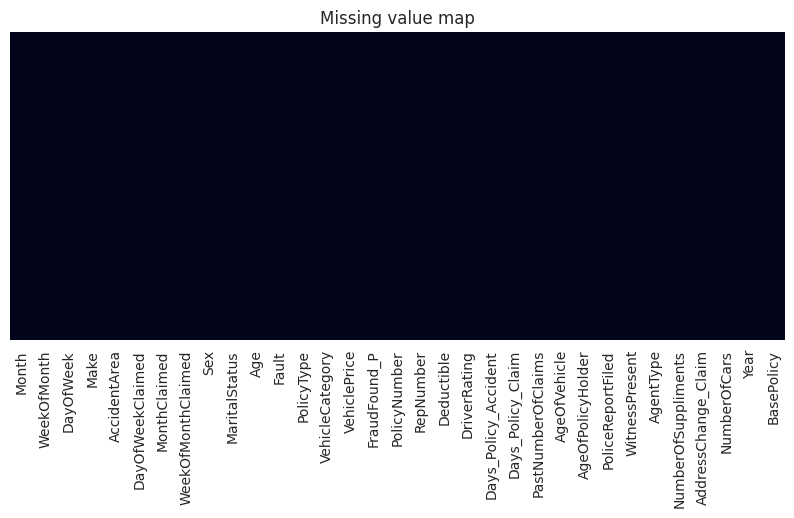

Age == 0: 320
DayOfWeekClaimed == '0': 1
MonthClaimed == '0': 1

Fully duplicated rows: 0
Duplicated ignoring PolicyNumber: 0

               count    pct
FraudFound_P              
0             14497  94.01
1               923   5.99


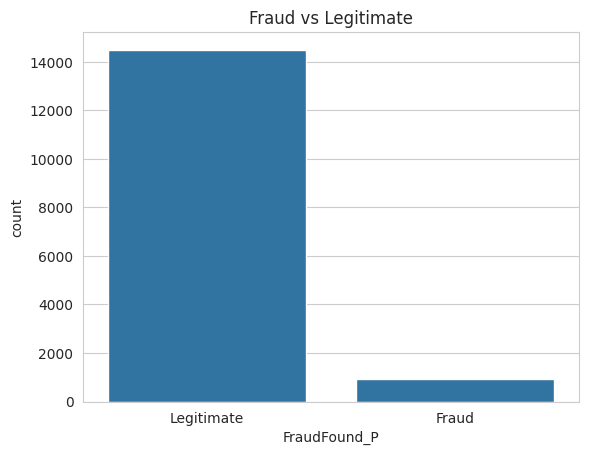

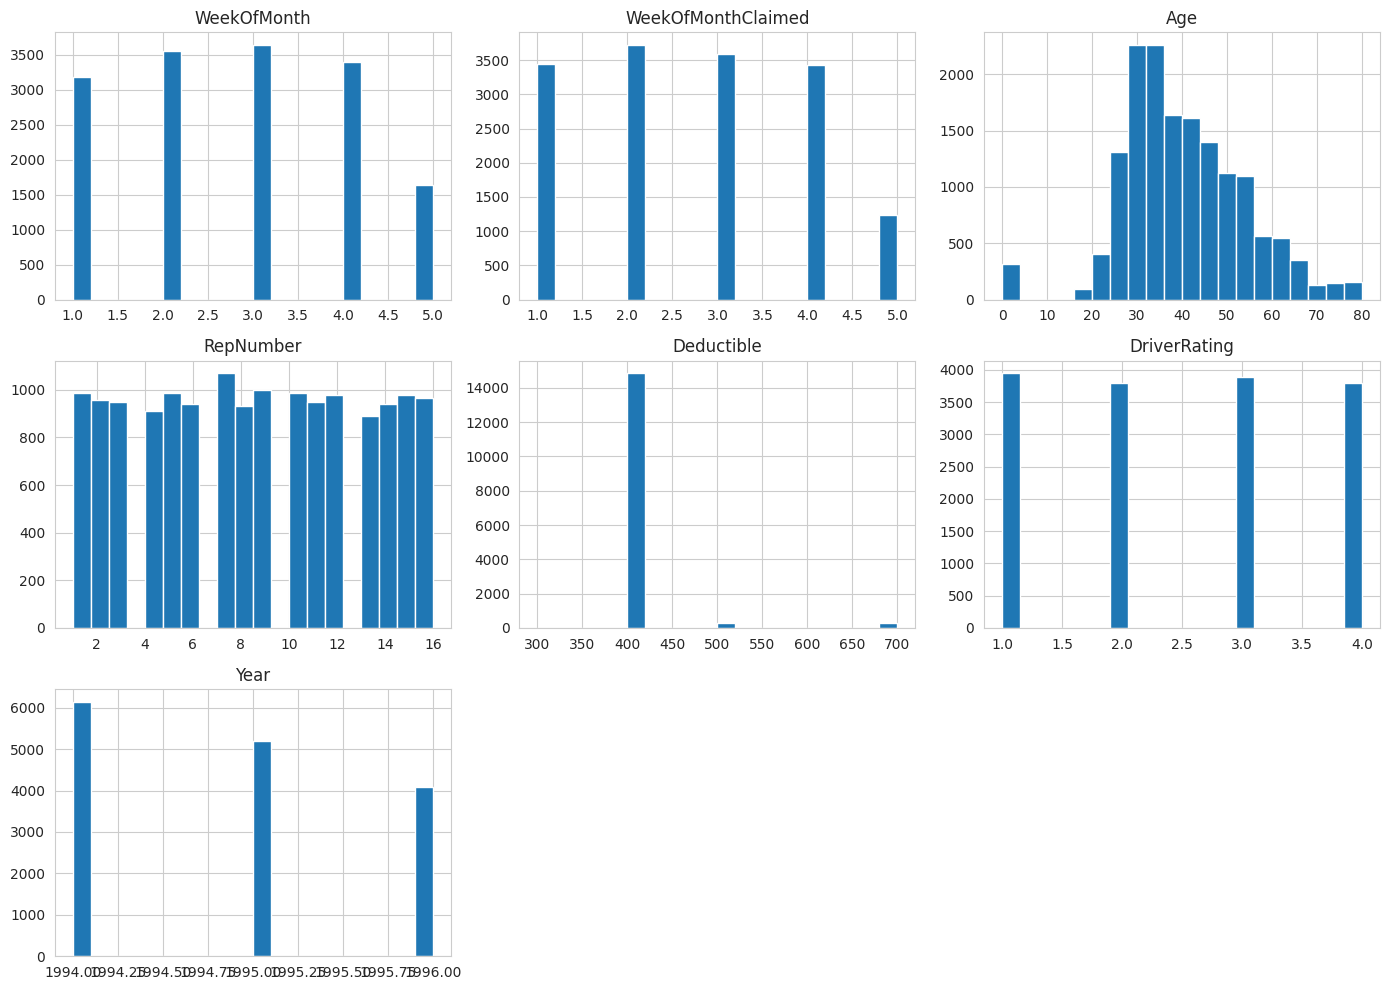

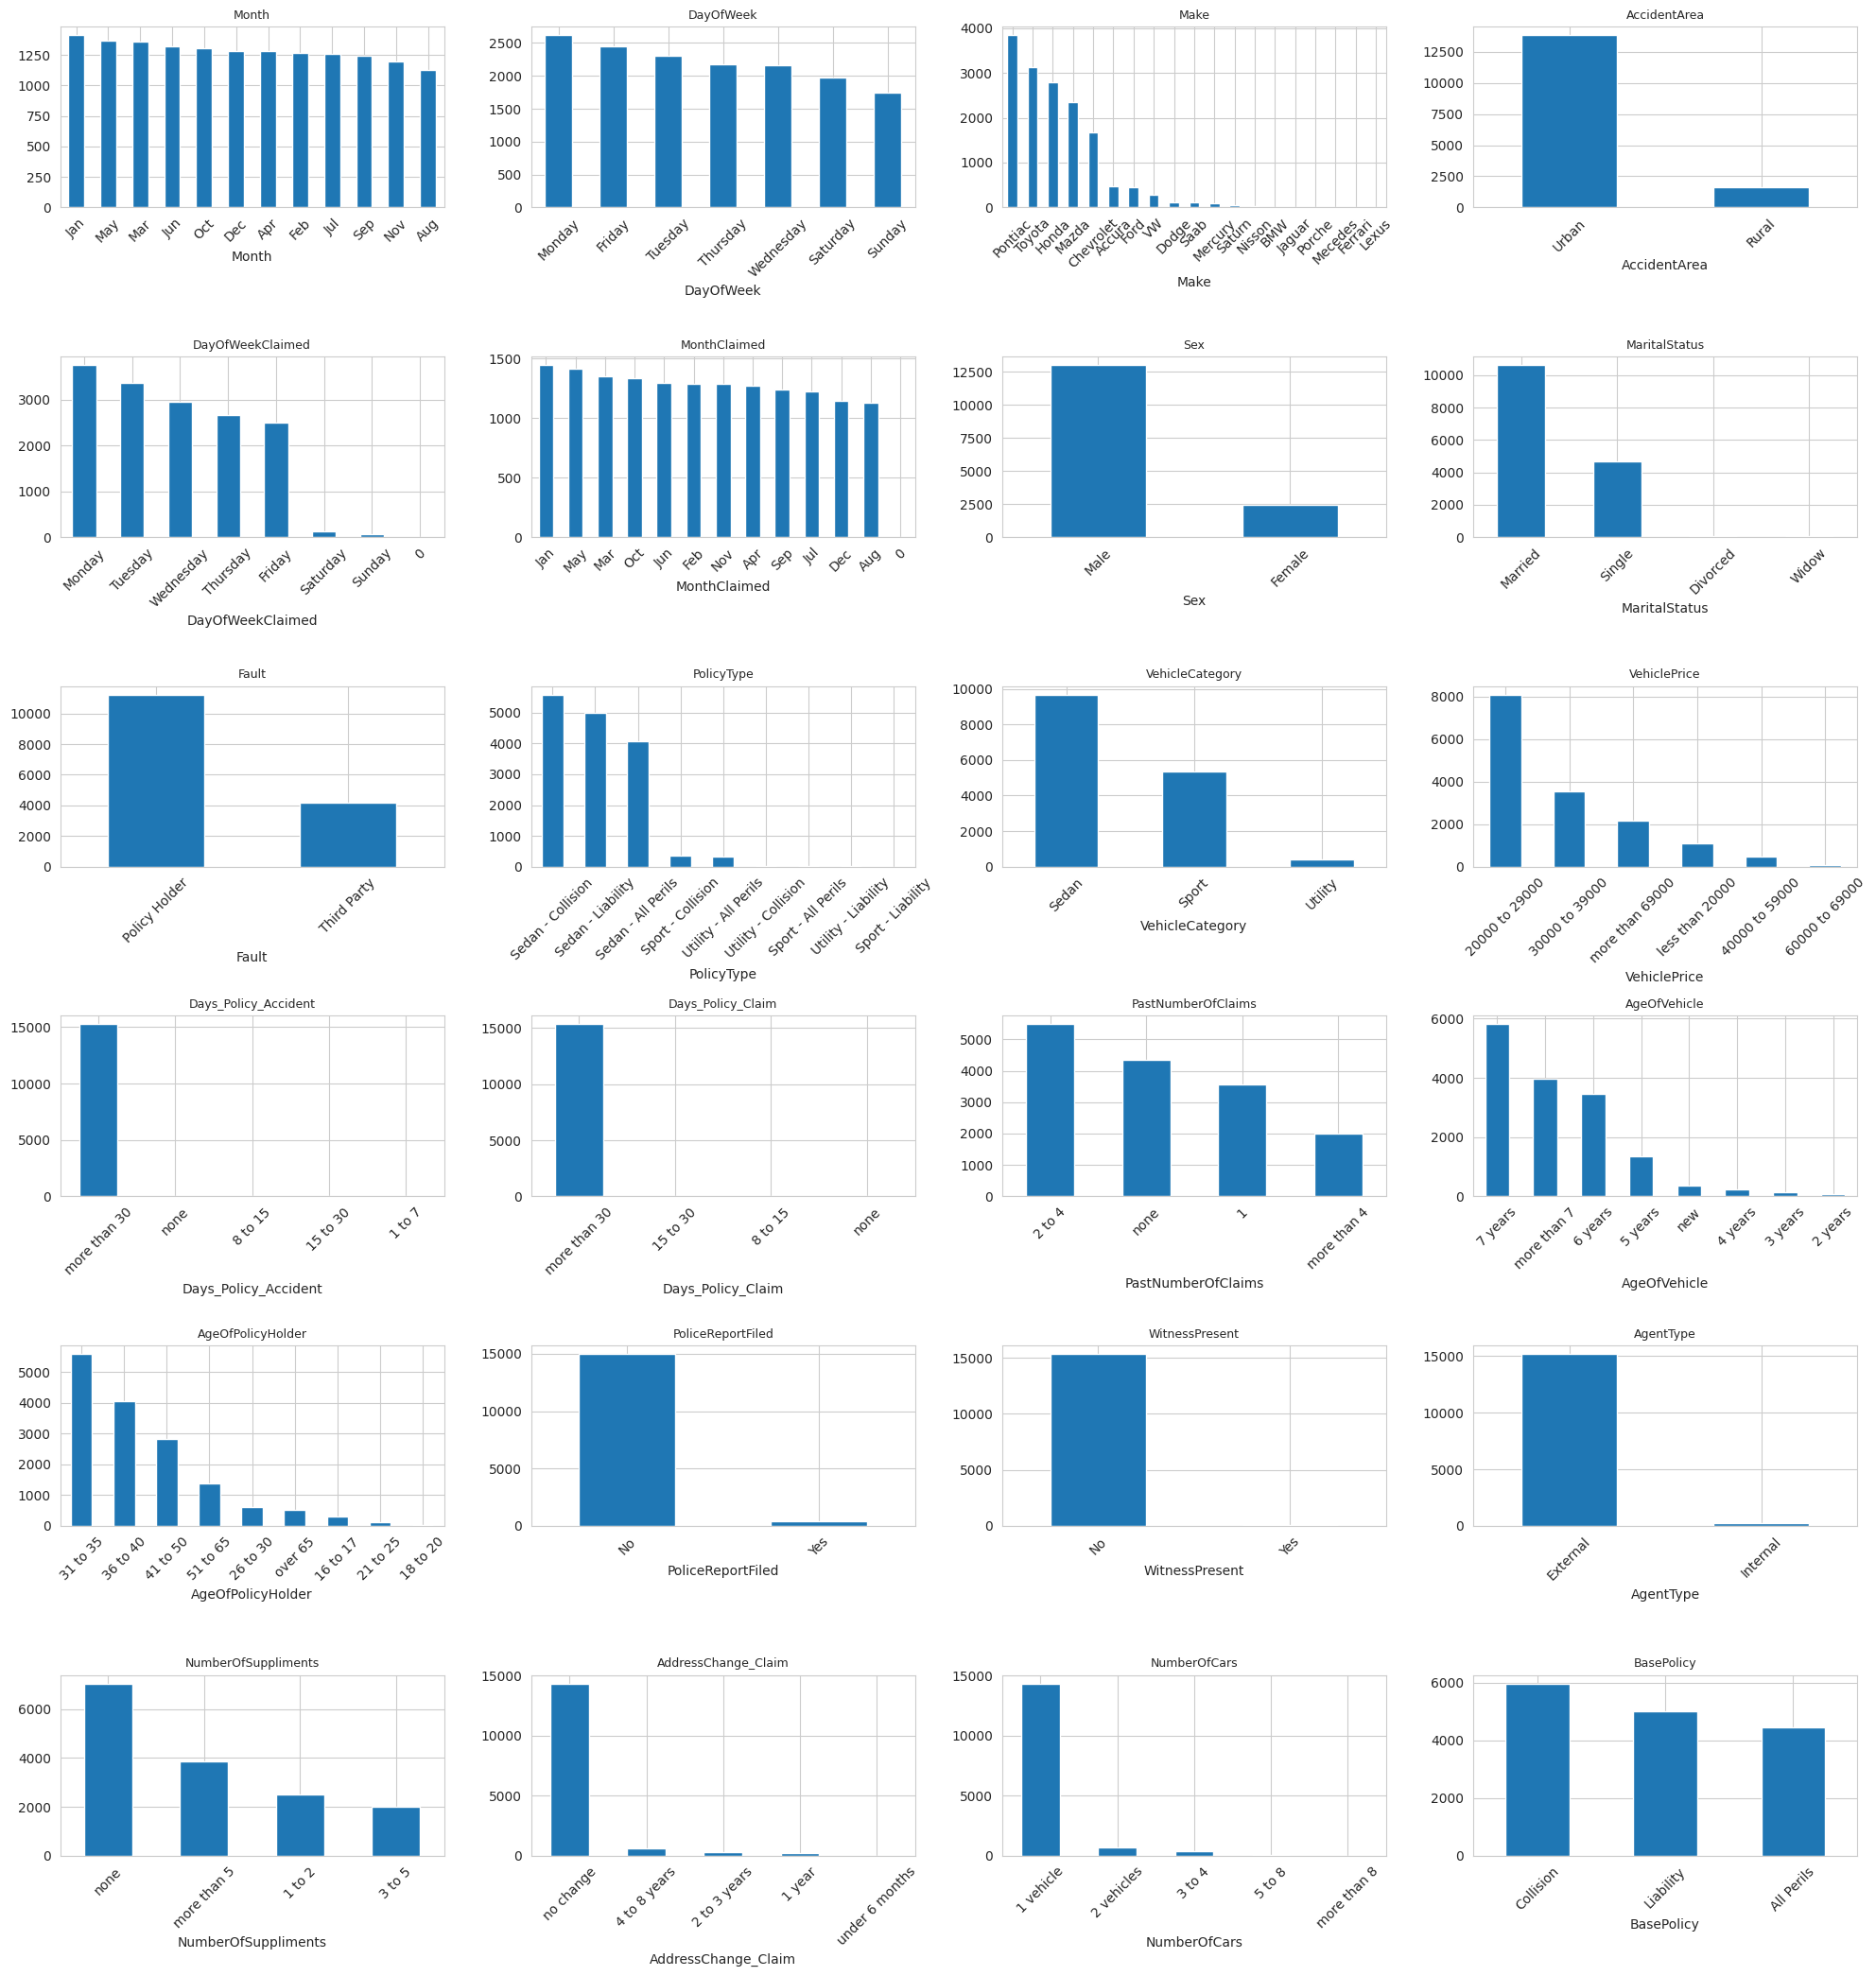

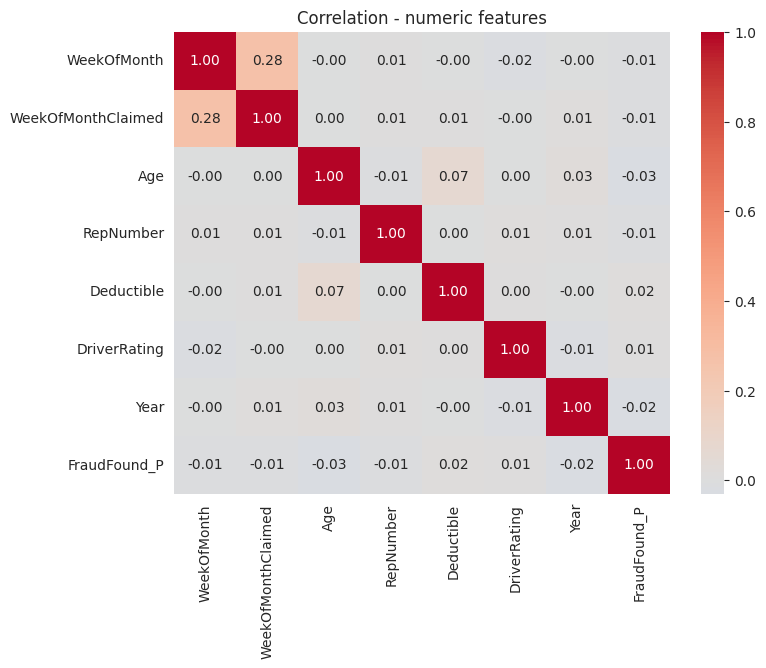


Top 10 |correlation| with target (rough, label-encoded):
 BasePolicy             0.157079
Fault                  0.131389
VehicleCategory        0.099198
VehiclePrice           0.061541
PolicyType             0.057057
AddressChange_Claim    0.037640
AccidentArea           0.033499
AgeOfPolicyHolder      0.031966
Sex                    0.029953
Age                    0.029741
Name: FraudFound_P, dtype: float64

Age IQR outliers: 547 (bounds 5.5-73.5)


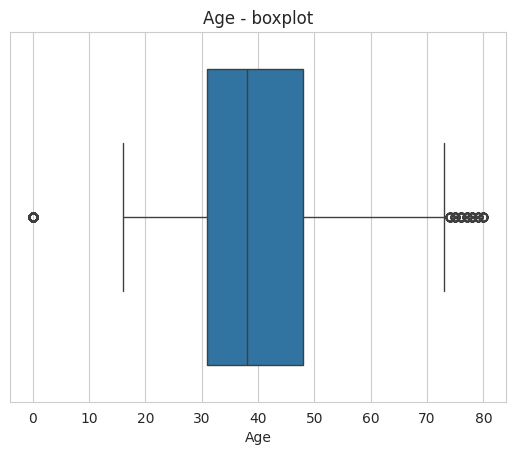

Age |z| > 3: 0

Cardinality per categorical column:
 Make                    19
MonthClaimed            13
Month                   12
PolicyType               9
AgeOfPolicyHolder        9
AgeOfVehicle             8
DayOfWeekClaimed         8
DayOfWeek                7
VehiclePrice             6
AddressChange_Claim      5
Days_Policy_Accident     5
NumberOfCars             5
PastNumberOfClaims       4
NumberOfSuppliments      4
MaritalStatus            4
Days_Policy_Claim        4
BasePolicy               3
VehicleCategory          3
Sex                      2
AccidentArea             2
Fault                    2
AgentType                2
PoliceReportFiled        2
WitnessPresent           2
dtype: int64

PolicyNumber unique vs rows: 15420 / 15420

Numeric feature means by target:
 FraudFound_P                  0            1
WeekOfMonth            2.792440     2.728061
WeekOfMonthClaimed     2.695799     2.665222
Age                   39.956957    38.265439
RepNumber              8.49

In [ ]:
# ============================================================
# IMPORTS
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif

sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

# ============================================================
# LOAD DATA
# ============================================================
df = pd.read_csv('dataset.csv', compression='zip', encoding='utf-8-sig')

TARGET = 'FraudFound_P'
ID_COLS = ['PolicyNumber']
print("Shape:", df.shape)

# ============================================================
# DATASET DESCRIPTION
# ============================================================
print(f"\nRows: {df.shape[0]}, Columns: {df.shape[1]}")
df.info()

numeric_cols = [c for c in df.select_dtypes(include='number').columns if c not in [TARGET] + ID_COLS]
categorical_cols = list(df.select_dtypes(include='object').columns)
print(f"\nNumeric predictors ({len(numeric_cols)}): {numeric_cols}")
print(f"Categorical predictors ({len(categorical_cols)}): {categorical_cols}")

print("\nNumeric summary:\n", df.describe(include='number').T)
print("\nCategorical summary:\n", df.describe(include='object').T)

# ============================================================
# MISSING-VALUE ANALYSIS
# ============================================================
missing = df.isnull().sum()
print("\nMissing values:\n", missing[missing > 0] if missing.sum() else "No explicit NaNs.")

plt.figure(figsize=(10, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title('Missing value map')
plt.show()

print("Age == 0:", (df['Age'] == 0).sum())
print("DayOfWeekClaimed == '0':", (df['DayOfWeekClaimed'] == '0').sum())
print("MonthClaimed == '0':", (df['MonthClaimed'] == '0').sum())

# ============================================================
# DUPLICATE ANALYSIS
# ============================================================
print("\nFully duplicated rows:", df.duplicated().sum())
print("Duplicated ignoring PolicyNumber:", df.drop(columns=ID_COLS).duplicated().sum())

# ============================================================
# CLASS DISTRIBUTION
# ============================================================
counts = df[TARGET].value_counts()
pct = df[TARGET].value_counts(normalize=True) * 100
print("\n", pd.DataFrame({'count': counts, 'pct': pct.round(2)}))

sns.countplot(x=TARGET, data=df)
plt.xticks([0, 1], ['Legitimate', 'Fraud'])
plt.title('Fraud vs Legitimate')
plt.show()

# ============================================================
# FEATURE DISTRIBUTIONS
# ============================================================
df[numeric_cols].hist(figsize=(14, 10), bins=20)
plt.tight_layout()
plt.show()

n = len(categorical_cols)
ncols = 4
nrows = -(-n // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(20, nrows * 3.5))
for ax, col in zip(axes.flatten(), categorical_cols):
    df[col].value_counts().plot(kind='bar', ax=ax)
    ax.set_title(col, fontsize=9)
    ax.tick_params(axis='x', labelrotation=45)
for ax in axes.flatten()[n:]:
    ax.axis('off')
plt.tight_layout()
plt.show()

# ============================================================
# CORRELATION MATRIX
# ============================================================
num_corr = df[numeric_cols + [TARGET]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(num_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation - numeric features')
plt.show()

df_enc = df.drop(columns=ID_COLS).copy()
for col in categorical_cols:
    df_enc[col] = LabelEncoder().fit_transform(df_enc[col].astype(str))

target_corr = df_enc.corr(numeric_only=True)[TARGET].drop(TARGET).abs().sort_values(ascending=False)
print("\nTop 10 |correlation| with target (rough, label-encoded):\n", target_corr.head(10))

# ============================================================
# OUTLIER ANALYSIS
# ============================================================
q1, q3 = df['Age'].quantile([.25, .75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
age_outliers = df[(df['Age'] < lower) | (df['Age'] > upper)]
print(f"\nAge IQR outliers: {len(age_outliers)} (bounds {lower:.1f}-{upper:.1f})")

sns.boxplot(x=df['Age'])
plt.title('Age - boxplot')
plt.show()

z = np.abs(stats.zscore(df['Age']))
print("Age |z| > 3:", (z > 3).sum())

# ============================================================
# CATEGORICAL CARDINALITY
# ============================================================
cardinality = df[categorical_cols].nunique().sort_values(ascending=False)
print("\nCardinality per categorical column:\n", cardinality)
print("\nPolicyNumber unique vs rows:", df['PolicyNumber'].nunique(), "/", len(df))

# ============================================================
# BASIC FEATURE ANALYSIS
# ============================================================
print("\nNumeric feature means by target:\n", df.groupby(TARGET)[numeric_cols].mean().T)

for col in ['Sex', 'VehicleCategory', 'Fault', 'AccidentArea']:
    rate = (df.groupby(col)[TARGET].mean() * 100).sort_values(ascending=False)
    print(f"\nFraud rate (%) by {col}:\n{rate.round(2)}")

# ============================================================
# FEATURE IMPORTANCE
# ============================================================
X = df_enc.drop(columns=[TARGET])
y = df_enc[TARGET]

mi = pd.Series(mutual_info_classif(X, y, random_state=42), index=X.columns).sort_values(ascending=False)
print("\nTop 10 by mutual information:\n", mi.head(10))

rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X, y)
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nTop 10 by Random Forest importance:\n", imp.head(10))

In [ ]:
# ============================================================
# PREPROCESSING
# ============================================================
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

df = pd.read_csv('dataset.csv', compression='zip', encoding='utf-8-sig')
TARGET = 'FraudFound_P'

# --- Deterministic data-quality fixes (safe pre-split: no fitted statistics involved) ---
df = df.drop(columns=['PolicyNumber'])  # ID column, no predictive meaning

make_fix = {'Mecedes': 'Mercedes', 'Nisson': 'Nissan', 'Porche': 'Porsche', 'Accura': 'Acura'}
df['Make'] = df['Make'].replace(make_fix)

corrupted = (df['DayOfWeekClaimed'] == '0') | (df['MonthClaimed'] == '0')
df = df[~corrupted].reset_index(drop=True)

df['Age'] = df['Age'].replace(0, np.nan)  # mark disguised-missing; impute after split, not before

# --- Split X / y ---
X = df.drop(columns=[TARGET])
y = df[TARGET]
numeric_cols = list(X.select_dtypes(include='number').columns)
categorical_cols = list(X.select_dtypes(include='object').columns)

# --- Train/test split BEFORE any fitted transform or resampling ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(f"Train: {X_train.shape}, fraud rate {y_train.mean():.4f}")
print(f"Test:  {X_test.shape}, fraud rate {y_test.mean():.4f}")

# --- Impute + scale numeric, one-hot encode categorical — fit on TRAIN, apply to both ---
numeric_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())
])
categorical_pipe = OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False)

preprocessor = ColumnTransformer([
    ('num', numeric_pipe, numeric_cols),
    ('cat', categorical_pipe, categorical_cols)
])

X_train_proc = preprocessor.fit_transform(X_train, y_train)
X_test_proc = preprocessor.transform(X_test)
print("Processed feature matrix:", X_train_proc.shape)

Train: (12335, 31), fraud rate 0.0598
Test:  (3084, 31), fraud rate 0.0600
Processed feature matrix: (12335, 119)


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [ ]:
# ============================================================
# BASELINE MODELS — 3 models x 3 imbalance strategies
# ============================================================
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, roc_auc_score

neg, pos = np.bincount(y_train)
scale_pos_weight = neg / pos

def get_models(strategy):
    if strategy == 'class_weight':
        return {
            'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
            'Random Forest': RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1),
            'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss', scale_pos_weight=scale_pos_weight)
        }
    return {
        'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
        'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
        'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss')
    }

fitted = {}  # (strategy, model_name) -> fitted model + predictions, reused by the cells below
results = []

for strategy in ['none', 'class_weight', 'smote']:
    if strategy == 'smote':
        # === SMOTE applied HERE ONLY: training fold, after the train/test split, inside this branch ===
        # X_test_proc / y_test are never touched — test keeps the native ~6% fraud rate throughout
        X_tr, y_tr = SMOTE(random_state=42).fit_resample(X_train_proc, y_train)
        print(f"[SMOTE] training fold rebalanced: {np.bincount(y_train)} -> {np.bincount(y_tr)}")
    else:
        X_tr, y_tr = X_train_proc, y_train

    for name, model in get_models(strategy).items():
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_test_proc)
        y_proba = model.predict_proba(X_test_proc)[:, 1]

        fitted[(strategy, name)] = {'y_pred': y_pred, 'y_proba': y_proba}
        results.append({
            'Strategy': strategy, 'Model': name,
            'Precision (fraud)': precision_score(y_test, y_pred, pos_label=1, zero_division=0),
            'Recall (fraud)': recall_score(y_test, y_pred, pos_label=1, zero_division=0),
            'F1 (fraud)': f1_score(y_test, y_pred, pos_label=1, zero_division=0),
            'Accuracy': accuracy_score(y_test, y_pred),
            'ROC-AUC': roc_auc_score(y_test, y_proba)
        })

results_df = pd.DataFrame(results).sort_values(['Strategy', 'F1 (fraud)'], ascending=[True, False])
print(results_df.round(4).to_string(index=False))

[SMOTE] training fold rebalanced: [11597   738] -> [11597 11597]
    Strategy               Model  Precision (fraud)  Recall (fraud)  F1 (fraud)  Accuracy  ROC-AUC
class_weight             XGBoost             0.2164          0.3568      0.2694    0.8839   0.8358
class_weight Logistic Regression             0.1309          0.8757      0.2277    0.6436   0.8079
class_weight       Random Forest             1.0000          0.0054      0.0108    0.9403   0.8319
        none             XGBoost             0.4054          0.0811      0.1351    0.9377   0.8473
        none       Random Forest             1.0000          0.0108      0.0214    0.9407   0.8266
        none Logistic Regression             0.2500          0.0108      0.0207    0.9387   0.8131
       smote Logistic Regression             0.1336          0.8216      0.2298    0.6696   0.8034
       smote             XGBoost             0.5161          0.0865      0.1481    0.9403   0.8560
       smote       Random Forest            

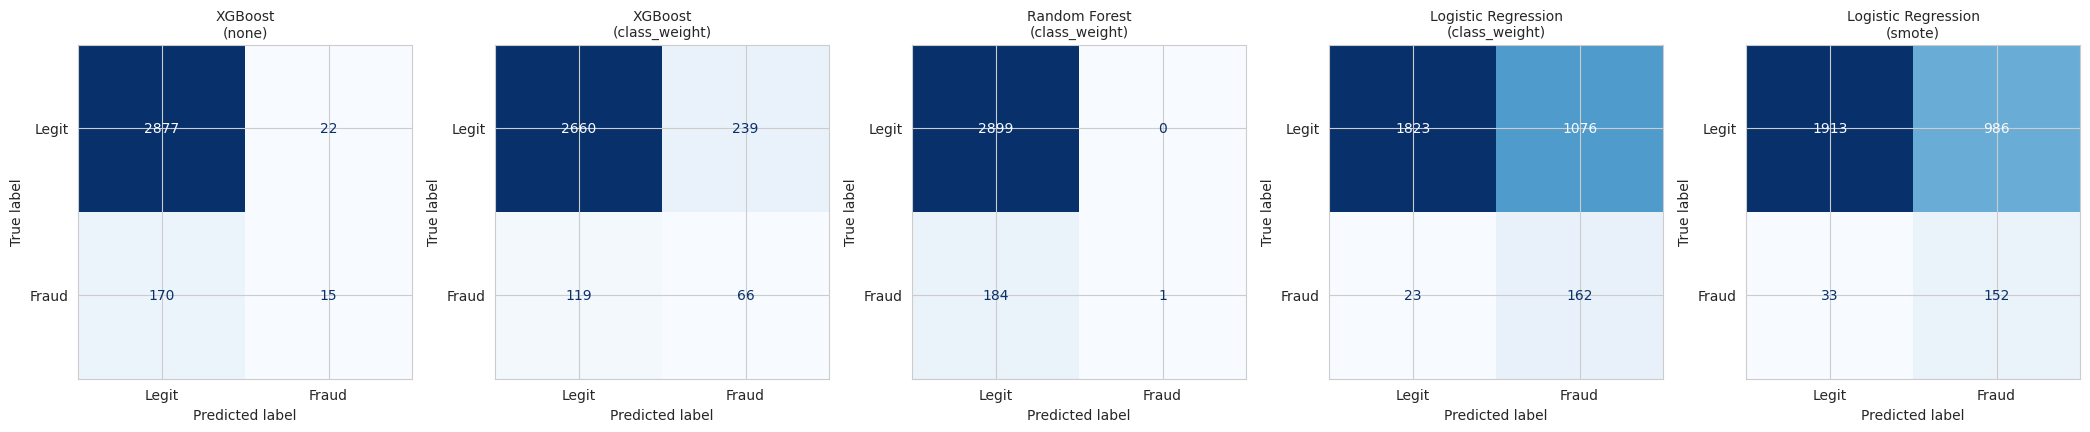

In [ ]:
# =====================
# CONFUSION MATRICES
# =====================
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

important = [
    ('none', 'XGBoost'),                       # baseline, no imbalance handling
    ('class_weight', 'XGBoost'),                # best overall F1
    ('class_weight', 'Random Forest'),          # stays near-blind to fraud even reweighted
    ('class_weight', 'Logistic Regression'),    # strongest rebalancing response
    ('smote', 'Logistic Regression'),           # SMOTE vs. class-weight, same model
]

fig, axes = plt.subplots(1, len(important), figsize=(4.2*len(important), 4.2))
for ax, (strategy, name) in zip(axes, important):
    cm = confusion_matrix(y_test, fitted[(strategy, name)]['y_pred'])
    ConfusionMatrixDisplay(cm, display_labels=['Legit', 'Fraud']).plot(
        ax=ax, colorbar=False, cmap='Blues', values_format='d'
    )
    ax.set_title(f"{name}\n({strategy})", fontsize=10)
plt.tight_layout()
plt.show()

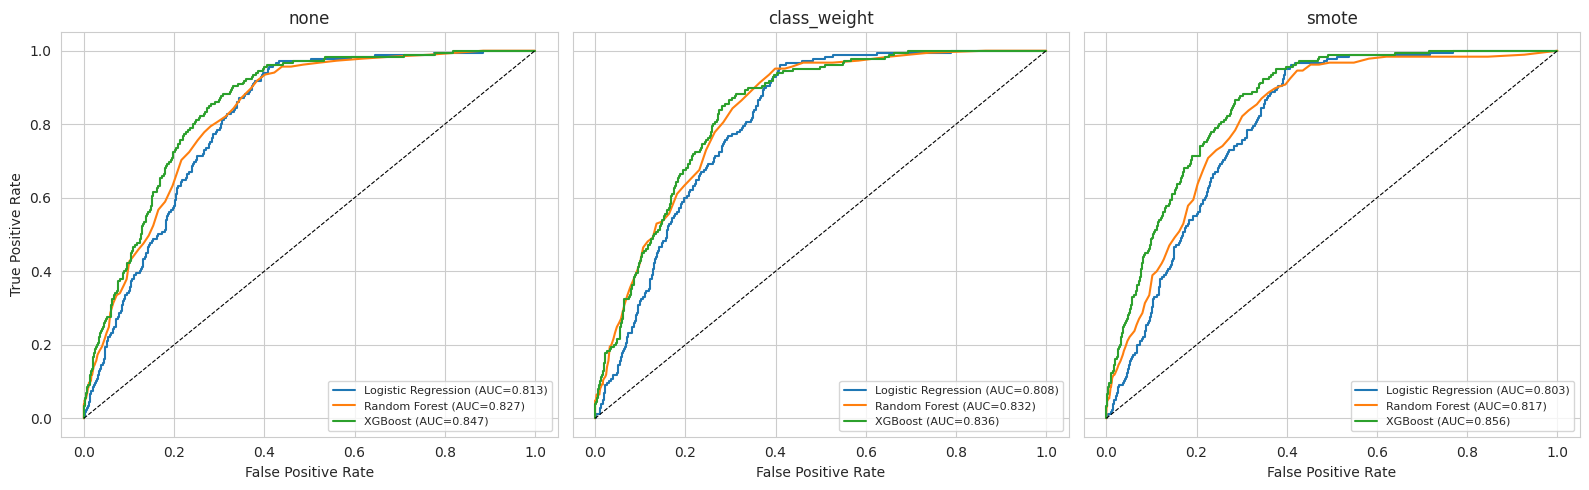

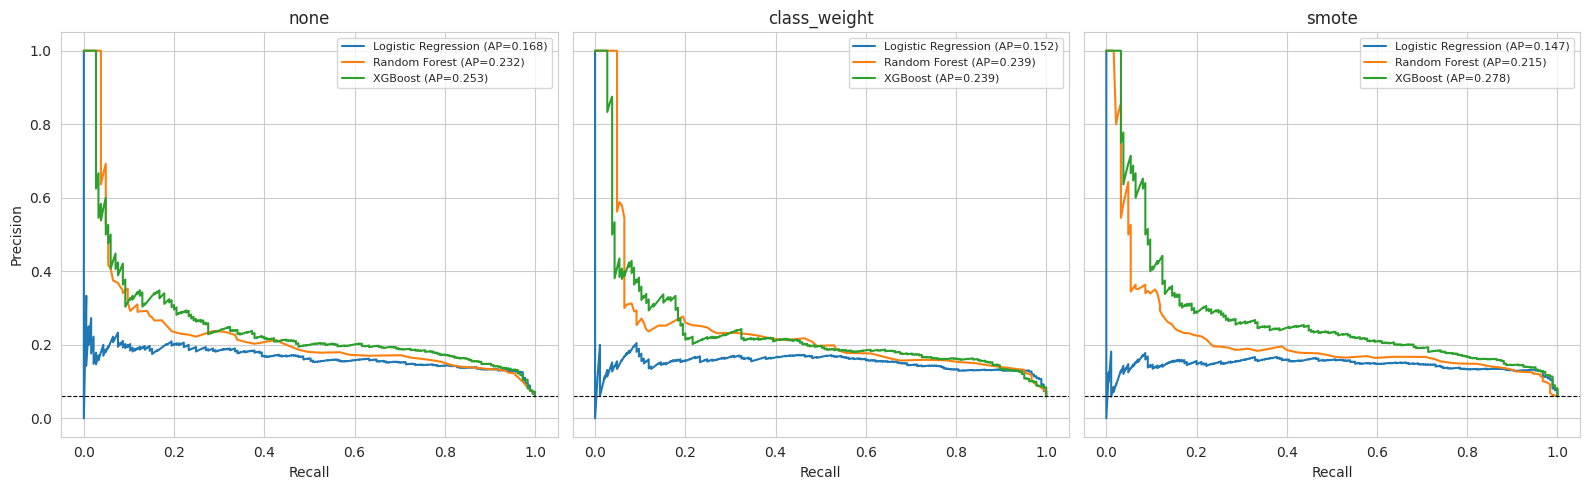

In [ ]:
# =======================================
# ROC and Precision-Recall curves
# =======================================
from sklearn.metrics import roc_curve, precision_recall_curve, auc, average_precision_score

strategies = ['none', 'class_weight', 'smote']
models = ['Logistic Regression', 'Random Forest', 'XGBoost']

# ROC
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, strategy in zip(axes, strategies):
    for name in models:
        fpr, tpr, _ = roc_curve(y_test, fitted[(strategy, name)]['y_proba'])
        ax.plot(fpr, tpr, label=f"{name} (AUC={auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], 'k--', linewidth=0.8)
    ax.set_title(strategy); ax.set_xlabel('False Positive Rate'); ax.legend(fontsize=8)
axes[0].set_ylabel('True Positive Rate')
plt.tight_layout(); plt.show()

# Precision-Recall
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, strategy in zip(axes, strategies):
    for name in models:
        yp = fitted[(strategy, name)]['y_proba']
        prec, rec, _ = precision_recall_curve(y_test, yp)
        ax.plot(rec, prec, label=f"{name} (AP={average_precision_score(y_test, yp):.3f})")
    ax.axhline(y_test.mean(), color='k', linestyle='--', linewidth=0.8)  # no-skill baseline
    ax.set_title(strategy); ax.set_xlabel('Recall'); ax.legend(fontsize=8)
axes[0].set_ylabel('Precision')
plt.tight_layout(); plt.show()

In [ ]:
# ============================================================
# 5-FOLD STRATIFIED CROSS-VALIDATION — resampling inside training folds only
# ============================================================
import time
import warnings
from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
                             roc_auc_score, average_precision_score)

# Expected: a rare category (e.g. a Make) can be absent from a training fold; handle_unknown='ignore' covers it
warnings.filterwarnings('ignore', message='Found unknown categories')

# CV runs on the training split only — X_test / y_test stay untouched as the final hold-out.
# (To cross-validate on the whole dataset instead: X_cv, y_cv = X, y)
X_cv, y_cv = X_train, y_train

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_rows = []
start = time.time()

for fold, (tr_idx, va_idx) in enumerate(skf.split(X_cv, y_cv), start=1):
    X_tr, X_va = X_cv.iloc[tr_idx], X_cv.iloc[va_idx]
    y_tr, y_va = y_cv.iloc[tr_idx], y_cv.iloc[va_idx]

    # Preprocessing (median, scaler mean/std, one-hot vocabulary) is fit on THIS training fold only
    prep = clone(preprocessor)
    X_tr_p = prep.fit_transform(X_tr, y_tr)
    X_va_p = prep.transform(X_va)

    neg_f, pos_f = np.bincount(y_tr)  # class ratio recomputed inside the training fold (XGBoost scale_pos_weight)

    for strategy in ['none', 'class_weight', 'smote']:
        if strategy == 'smote':
            # === SMOTE applied HERE ONLY: this training fold, inside the CV loop ===
            # The validation fold (X_va_p, y_va) is never resampled and keeps the native ~6% fraud rate
            X_fit, y_fit = SMOTE(random_state=42).fit_resample(X_tr_p, y_tr)
            print(f"[fold {fold}] SMOTE on training fold: {np.bincount(y_tr)} -> {np.bincount(y_fit)} "
                  f"| validation fold untouched: {np.bincount(y_va)}")
        else:
            X_fit, y_fit = X_tr_p, y_tr

        models = get_models(strategy)
        if strategy == 'class_weight':
            models['XGBoost'].set_params(scale_pos_weight=neg_f / pos_f)

        for name, model in models.items():
            model.fit(X_fit, y_fit)
            y_pred = model.predict(X_va_p)
            y_proba = model.predict_proba(X_va_p)[:, 1]
            cv_rows.append({
                'Fold': fold, 'Strategy': strategy, 'Model': name,
                'Precision': precision_score(y_va, y_pred, pos_label=1, zero_division=0),
                'Recall': recall_score(y_va, y_pred, pos_label=1, zero_division=0),
                'F1': f1_score(y_va, y_pred, pos_label=1, zero_division=0),
                'Accuracy': accuracy_score(y_va, y_pred),
                'ROC-AUC': roc_auc_score(y_va, y_proba),
                'PR-AUC (AP)': average_precision_score(y_va, y_proba),
            })

print(f"\nCV finished in {time.time() - start:.0f}s")
cv_df = pd.DataFrame(cv_rows)  # one row per fold x strategy x model (45 rows)

# --- Summary: mean ± std across the 5 folds, ranked by mean F1 ---
metrics = ['Precision', 'Recall', 'F1', 'Accuracy', 'ROC-AUC', 'PR-AUC (AP)']
agg = cv_df.groupby(['Strategy', 'Model'])[metrics].agg(['mean', 'std'])
agg = agg.sort_values(('F1', 'mean'), ascending=False)
cv_summary = pd.DataFrame({
    m: agg[(m, 'mean')].map('{:.3f}'.format) + ' ± ' + agg[(m, 'std')].map('{:.3f}'.format)
    for m in metrics
})
display(cv_summary)

[fold 1] SMOTE on training fold: [9278  590] -> [9278 9278] | validation fold untouched: [2319  148]
[fold 2] SMOTE on training fold: [9278  590] -> [9278 9278] | validation fold untouched: [2319  148]
[fold 3] SMOTE on training fold: [9278  590] -> [9278 9278] | validation fold untouched: [2319  148]
[fold 4] SMOTE on training fold: [9277  591] -> [9277 9277] | validation fold untouched: [2320  147]
[fold 5] SMOTE on training fold: [9277  591] -> [9277 9277] | validation fold untouched: [2320  147]

CV finished in 79s


Precision         Recall             F1  \
Strategy     Model                                                              
class_weight XGBoost              0.215 ± 0.019  0.310 ± 0.038  0.254 ± 0.024   
smote        Logistic Regression  0.134 ± 0.006  0.791 ± 0.020  0.229 ± 0.009   
class_weight Logistic Regression  0.131 ± 0.006  0.844 ± 0.032  0.226 ± 0.010   
smote        XGBoost              0.443 ± 0.114  0.081 ± 0.024  0.137 ± 0.039   
none         XGBoost              0.413 ± 0.066  0.081 ± 0.022  0.135 ± 0.033   
smote        Random Forest        0.653 ± 0.357  0.012 ± 0.003  0.024 ± 0.006   
none         Logistic Regression  0.277 ± 0.218  0.009 ± 0.008  0.018 ± 0.015   
             Random Forest        0.800 ± 0.447  0.007 ± 0.005  0.013 ± 0.009   
class_weight Random Forest        0.700 ± 0.447  0.005 ± 0.003  0.011 ± 0.006   

                                       Accuracy        ROC-AUC    PR-AUC (AP)  
Strategy     Model                                                             
class_weight XGBoost              0.891 ± 0.005  0.830 ± 0.010  0.247 ± 0.030  
smote        Logistic Regression  0.681 ± 0.012  0.795 ± 0.006  0.157 ± 0.013  
class_weight Logistic Regression  0.655 ± 0.012  0.797 ± 0.003  0.156 ± 0.015  
smote        XGBoost              0.939 ± 0.002  0.840 ± 0.011  0.248 ± 0.033  
none         XGBoost              0.938 ± 0.001  0.832 ± 0.009  0.237 ± 0.028  
smote        Random Forest        0.940 ± 0.001  0.804 ± 0.006  0.189 ± 0.010  
none         Logistic Regression  0.939 ± 0.001  0.793 ± 0.005  0.163 ± 0.010  
             Random Forest        0.941 ± 0.000  0.808 ± 0.009  0.246 ± 0.044  
class_weight Random Forest        0.940 ± 0.000  0.815 ± 0.006  0.240 ± 0.033